# Session 7 — English execution copy
Adapted from Dr. Loveleen Gaur's supplied notebook. Public teaching data and synthetic experiments; NOT company mining records.

The original file is retained locally, not republished. Original SHA-256: `4fcdb3f5bcab9c2086ef62fa141667bdfdf5b4c242810280838f236abcb3016d`.

English adaptation, execution, and supplementary summaries were prepared with AI assistance. The student must review and repeat the work. Original teaching claims are not automatically endorsed.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
import matplotlib
matplotlib.use('Agg')


# Session 7 — Benchmarking, Ablation Studies & Reporting Standards
### Hands-on Lab · Research Methods & Scientific Integrity in AI
**UNMSM Doctoral Program in Deep Technologies · Dr. Loveleen Gaur**

---

**What you will do tonight (no GPU required — everything runs on the free CPU tier in a few minutes):**

| # | Exercise | The rigor it builds |
|---|----------|---------------------|
| 1 | Weak vs. tuned baseline | A "win" against an *untuned* baseline is not a win |
| 2 | Seeds & variance | One lucky seed is not a result — report mean ± std |
| 3 | Ablation study | Attribute the gain to a specific component |
| 4 | Generate a Model Card | Mitchell et al. (2019) — 9 sections |
| 5 | Generate a Datasheet | Gebru et al. (2021) — 7 sections |
| 6 | Documentation scorecard | Self-audit completeness & reproducibility |

**Part B — extension (depth + portfolio):**

| # | Exercise | The rigor it builds |
|---|----------|---------------------|
| 7 | Significance & confidence intervals | Test a difference before you claim it |
| 8 | Compute-matched comparison | A bigger budget is a different experiment |
| 9 | The data-leakage trap | Leakage can manufacture accuracy from noise |
| 10 | Ablation error bars + multiple comparisons | Visualise attribution; correct for many tests |
| 11 | EU AI Act · Annex IV crosswalk | Turn the Model Card into a compliance gap table |
| 12 | Reproducibility report bundle | Zip a submission a stranger could re-run |

**How to use this notebook:** run the cells top to bottom (`Shift+Enter`). Cells marked **🛠 YOUR TURN** are where you edit. Cells marked **🧪** produce a result to discuss.

> Every empirical claim in tonight's slides is sourced. Full reference list is on the last slide.

<hr>

## 0 · Setup
Run once. Installs nothing extra — all of this ships with Colab.

<hr>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (7, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
data = load_breast_cancer()
X, y = (data.data, data.target)
feature_names = list(data.feature_names)
print(f'Dataset: {data.DESCR.splitlines()[0]}')
print(f'Samples: {X.shape[0]} | Features: {X.shape[1]} | Classes: {np.bincount(y)} (0=malignant, 1=benign)')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape[0]}  Test: {X_test.shape[0]}')


Dataset: .. _breast_cancer_dataset:
Samples: 569 | Features: 30 | Classes: [212 357] (0=malignant, 1=benign)
Train: 426  Test: 143


## Exercise 1 · The weak-baseline illusion
**The hook, in code.** Dacrema et al. (2019) found that 6 of 7 reproducible neural recommenders were beaten by *simple, well-tuned* heuristics. The villain was rarely the fancy model — it was the **lazy baseline**.

Here we play both roles:
- a **"fancy" model** (gradient boosting) that we tune a little, and
- a **logistic-regression baseline** that we first leave *untuned*, then tune *as hard as the fancy model*.

Watch the "improvement" shrink — or vanish — once the baseline gets a fair shake.

<hr>

In [3]:
fancy = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE))
fancy.fit(X_train, y_train)
acc_fancy = accuracy_score(y_test, fancy.predict(X_test))
weak = make_pipeline(StandardScaler(), LogisticRegression(C=0.001, max_iter=2000, random_state=RANDOM_STATE))
weak.fit(X_train, y_train)
acc_weak = accuracy_score(y_test, weak.predict(X_test))
print(f'Fancy model (gradient boosting)        : {acc_fancy:.4f}')
print(f'UNTUNED baseline (logistic, C=0.001)   : {acc_weak:.4f}')
print(f'Apparent improvement over weak baseline: {acc_fancy - acc_weak:+.4f}  <-- looks impressive!')


C:\Users\1153\Documents\Codex\2026-10-24\de\work\portfolio-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
Fancy model (gradient boosting)        : 0.9580
UNTUNED baseline (logistic, C=0.001)   : 0.9161
Apparent improvement over weak baseline: +0.0420  <-- looks impressive!


In [4]:
param_grid = {'logisticregression__C': np.logspace(-3, 2, 12)}
strong = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)), param_grid, cv=5, scoring='accuracy', n_jobs=1)
strong.fit(X_train, y_train)
acc_strong = accuracy_score(y_test, strong.predict(X_test))
print(f'Fancy model                            : {acc_fancy:.4f}')
print(f"TUNED baseline (best C={strong.best_params_['logisticregression__C']:.4g}) : {acc_strong:.4f}")
print(f'HONEST improvement over tuned baseline : {acc_fancy - acc_strong:+.4f}')
print()
print("Discuss: how much of the original 'improvement' survived a fair comparison?")


C:\Users\1153\Documents\Codex\2026-10-24\de\work\portfolio-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\1153\Documents\Codex\2026-10-24\de\work\portfolio-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\1153\Documents\Codex\2026-10-24\de\work\portfolio-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\1153\Documents\Codex\2026-10-24\de\work\portfolio-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
C:\Users\1153\Documents\Codex\2026-10-24\de\work\portfolio-venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


**🧪 Discuss.** The first comparison flattered the fancy model because the baseline was crippled (`C=0.001` heavily under-regularised it). The fairness test from the slides: *if a reviewer tuned your baseline with the same care you gave your model, would your gain survive?*

> The lesson is **not** "boosting is bad." It is: a comparison is only a comparison when both sides got equal effort, equal data, equal compute.

<hr>

## Exercise 2 · One seed is not a result
A single training run reports a single number. But stochastic training (initialisation, data order, sampling) means that number is **a draw from a distribution**. Reporting one draw is how a paper claims "89.7% beats 89.2%" when the real difference is noise (the Session 6 story).

We run the fancy model over **10 seeds** and look at the spread.

<hr>

In [5]:
seeds = range(10)
accs = []
for s in seeds:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=s)
    m = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=s))
    m.fit(Xtr, ytr)
    accs.append(accuracy_score(yte, m.predict(Xte)))
accs = np.array(accs)
print('Per-seed accuracies:', np.round(accs, 4))
print(f'\nMean ± std : {accs.mean():.4f} ± {accs.std():.4f}')
print(f'Min / Max  : {accs.min():.4f} / {accs.max():.4f}   (spread = {accs.max() - accs.min():.4f})')
print(f"\nIf you reported only the BEST seed you'd claim {accs.max():.4f}.")
print(f"If you reported only the WORST seed you'd claim {accs.min():.4f}.")
print('Same model, same data, same code. The only thing that changed was the seed.')


Per-seed accuracies: [0.951 0.958 0.972 0.958 0.979 0.979 0.979 0.965 0.972 0.972]

Mean ± std : 0.9685 ± 0.0095
Min / Max  : 0.9510 / 0.9790   (spread = 0.0280)

If you reported only the BEST seed you'd claim 0.9790.
If you reported only the WORST seed you'd claim 0.9510.
Same model, same data, same code. The only thing that changed was the seed.


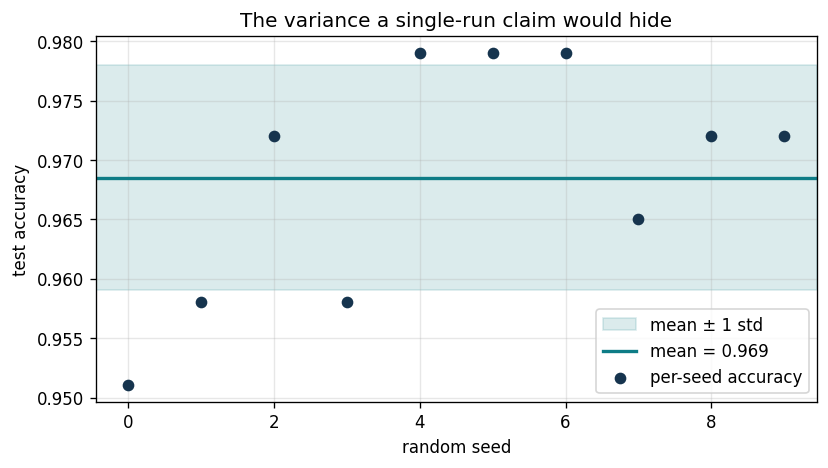

In [6]:
plt.figure()
plt.axhspan(accs.mean() - accs.std(), accs.mean() + accs.std(), color='#0E7C86', alpha=0.15, label='mean ± 1 std')
plt.axhline(accs.mean(), color='#0E7C86', lw=2, label=f'mean = {accs.mean():.3f}')
plt.scatter(list(seeds), accs, color='#16344E', zorder=5, label='per-seed accuracy')
plt.xlabel('random seed')
plt.ylabel('test accuracy')
plt.title('The variance a single-run claim would hide')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


**🧪 Discuss.** Best practice (NeurIPS / ICML reproducibility checklists): report **mean ± std over ≥5 seeds**, and ideally a statistical test before claiming one method beats another. A "+0.3%" gain inside a ±0.8% band is not a finding.

<hr>

## Exercise 3 · A proper ablation study
An ablation removes **one component at a time** to attribute the gain. Here the "components" are groups of input features, plus the scaling step. We turn each off, keep everything else fixed, and measure the drop — reporting **mean ± std over seeds**, never a single run.

<hr>

In [7]:
def feature_block(prefix):
    return [i for i, n in enumerate(feature_names) if n.startswith(prefix)]
blocks = {'mean features': feature_block('mean'), 'error features': feature_block('radius error') + [i for i, n in enumerate(feature_names) if 'error' in n], 'worst features': feature_block('worst')}
blocks['error features'] = sorted(set(blocks['error features']))

def evaluate(use_idx, scale=True, seeds=range(10)):
    scores = []
    for s in seeds:
        Xtr, Xte, ytr, yte = train_test_split(X[:, use_idx], y, test_size=0.25, stratify=y, random_state=s)
        steps = [StandardScaler()] if scale else []
        steps.append(GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=s))
        m = make_pipeline(*steps)
        m.fit(Xtr, ytr)
        scores.append(accuracy_score(yte, m.predict(Xte)))
    return (np.mean(scores), np.std(scores))
all_idx = list(range(X.shape[1]))
rows = []
full_mean, full_std = evaluate(all_idx)
rows.append(('FULL model (all features + scaling)', full_mean, full_std, 0.0))
for name, idx in blocks.items():
    keep = [i for i in all_idx if i not in idx]
    m_, s_ = evaluate(keep)
    rows.append((f'– remove {name}', m_, s_, m_ - full_mean))
m_, s_ = evaluate(all_idx, scale=False)
rows.append(('– remove feature scaling', m_, s_, m_ - full_mean))
abl = pd.DataFrame(rows, columns=['Configuration', 'Accuracy (mean)', 'Std', 'Δ vs full'])
abl[['Accuracy (mean)', 'Std', 'Δ vs full']] = abl[['Accuracy (mean)', 'Std', 'Δ vs full']].round(4)
abl


                      Configuration  Accuracy (mean)    Std  Δ vs full
FULL model (all features + scaling)           0.9685 0.0095     0.0000
             – remove mean features           0.9629 0.0133    -0.0056
            – remove error features           0.9671 0.0129    -0.0014
            – remove worst features           0.9483 0.0183    -0.0203
           – remove feature scaling           0.9685 0.0095     0.0000

**🧪 Read the table.** The components with the **most negative Δ** are doing the most work; a near-zero Δ means a component barely earns its place — and saying so is an honest **negative result**, exactly the kind the literature under-reports.

**🛠 YOUR TURN.** Change `seeds=range(5)` to `range(10)` in `evaluate`, or regroup the feature blocks, and see whether your conclusions are stable. Stability across seeds is what makes an ablation trustworthy.

<hr>

## Exercise 4 · Generate a Model Card
A **Model Card** (Mitchell et al., 2019) is a short document that travels with a trained model. The nine sections are below. Fill the dictionary **honestly** — where you don't know, write `"UNKNOWN — to investigate"` rather than leaving it blank. The gaps are the point.

<hr>

In [8]:
model_card = {'Model details': {'Name / version': 'BreastCancer-GBM v0.1', 'Owner / contact': 'Course demonstration; student review pending', 'Date': '2026-10-24', 'Architecture': 'Gradient Boosting (200 trees, depth 3) on standardised features', 'License': 'UNKNOWN — to investigate'}, 'Intended use': {'Primary intended uses': 'Teaching example for documentation practice ONLY.', 'Out-of-scope / misuse': 'NOT for clinical decisions. Trained on one historical dataset; not validated on any hospital population.', 'Intended users': 'Doctoral students in this course'}, 'Factors': {'Relevant groups / conditions': 'Tumour type (malignant vs benign). Real clinical factors (age, scanner, site) are ABSENT from this dataset.', 'Evaluation factors': 'Reported overall and per class.'}, 'Metrics': {'Performance measures': 'Accuracy and macro-F1', 'Decision thresholds': '0.5 default', 'Variation approach': 'Mean ± population std over 10 split/model seeds; single-split metrics are labelled separately'}, 'Evaluation data': {'Datasets': '25% held-out stratified split of the Wisconsin Breast Cancer dataset', 'Preprocessing': 'StandardScaler fit on the training split only'}, 'Training data': {'Datasets': '75% of the Wisconsin Breast Cancer dataset (569 samples total)', 'Known limitations': 'Single source, historical, no demographic metadata'}, 'Quantitative analyses': {'Overall results': 'filled automatically below', 'Disaggregated results': 'filled automatically below'}, 'Ethical considerations': {'Risks': 'False reassurance if mistaken for a clinical tool; dataset lacks demographic diversity.', 'Mitigations': 'Clearly marked educational; no deployment.'}, 'Caveats and recommendations': {'Caveats': 'Performance will NOT transfer to real clinical imaging or other populations.', 'Recommendations': 'External validation required before any real use.'}}
print('Dictionary ready — render it in the next cell.')


Dictionary ready — render it in the next cell.


In [9]:
final = make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE))
final.fit(X_train, y_train)
pred = final.predict(X_test)
overall_acc = accuracy_score(y_test, pred)
overall_f1 = f1_score(y_test, pred, average='macro')
per_class = {data.target_names[c]: round(float((pred[y_test == c] == c).mean()), 4) for c in [0, 1]}
model_card['Quantitative analyses']['Overall results'] = f'accuracy={overall_acc:.4f}, macro-F1={overall_f1:.4f}'
model_card['Quantitative analyses']['Disaggregated results'] = f'per-class recall: {per_class}'

def render_card(card, title='Model Card'):
    lines = [f'# {title}', '']
    for section, fields in card.items():
        lines.append(f'## {section}')
        for k, v in fields.items():
            lines.append(f'- **{k}:** {v}')
        lines.append('')
    return '\n'.join(lines)
card_md = render_card(model_card)
print(card_md)
with open('model_card.md', 'w', encoding='utf-8') as f:
    f.write(card_md)
print('\n✅ Saved to model_card.md  (File > Download, or right-click in the file panel)')


# Model Card

## Model details
- **Name / version:** BreastCancer-GBM v0.1
- **Owner / contact:** Course demonstration; student review pending
- **Date:** 2026-10-24
- **Architecture:** Gradient Boosting (200 trees, depth 3) on standardised features
- **License:** UNKNOWN — to investigate

## Intended use
- **Primary intended uses:** Teaching example for documentation practice ONLY.
- **Out-of-scope / misuse:** NOT for clinical decisions. Trained on one historical dataset; not validated on any hospital population.
- **Intended users:** Doctoral students in this course

## Factors
- **Relevant groups / conditions:** Tumour type (malignant vs benign). Real clinical factors (age, scanner, site) are ABSENT from this dataset.
- **Evaluation factors:** Reported overall and per class.

## Metrics
- **Performance measures:** Accuracy and macro-F1
- **Decision thresholds:** 0.5 default
- **Variation approach:** Mean ± population std over 10 split/model seeds; single-split metrics are labelled s

**🧪 Notice** the *Factors* section forces an uncomfortable admission: this dataset has **no demographic metadata**, so we literally cannot disaggregate by the factors that matter clinically. A Model Card makes that blind spot visible instead of hiding it behind an average.

<hr>

## Exercise 5 · Generate a Datasheet
A **Datasheet** (Gebru et al., 2021) documents the *dataset*, across seven lifecycle sections. Same rule: honesty over completeness. `"UNKNOWN — to investigate"` is a valid, useful answer.

<hr>

In [10]:
datasheet = {'Motivation': {'Purpose': 'Originally created to study automated diagnosis of breast masses from FNA imaging features.', 'Created by / funded by': 'Originating clinical researchers (UCI ML Repository). Funding: UNKNOWN — to investigate.'}, 'Composition': {'What instances represent': '569 fine-needle-aspirate samples, each with 30 computed cell-nucleus features.', 'Labels': 'Binary: malignant / benign.', 'Sample vs population': 'A sample; NOT all possible patients. No demographic attributes recorded.', 'Missing data': 'None reported in features; demographics entirely absent.'}, 'Collection process': {'How collected': 'Image analysis of digitized FNA slides; features computed automatically.', 'Timeframe': 'Historical (1990s). Distribution may not reflect current populations.', 'Consent / ethics': 'UNKNOWN — to investigate (predates modern consent documentation norms).'}, 'Preprocessing / cleaning / labeling': {'Steps': 'Features pre-computed; we additionally apply StandardScaler at train time (fit on train split only).', 'Raw data available': 'Raw images NOT included — only derived features.'}, 'Uses': {'Appropriate uses': 'Methods teaching, benchmarking documentation practice.', 'Should NOT be used for': 'Real clinical decisions or as evidence about any present-day population.'}, 'Distribution': {'How distributed': 'Public via UCI ML Repository / scikit-learn.', 'License / restrictions': 'UNKNOWN — to investigate.'}, 'Maintenance': {'Maintainer': 'No active maintainer; static historical dataset.', 'Update plan': 'None expected.'}}

def render_card(card, title):
    lines = [f'# {title}', '']
    for section, fields in card.items():
        lines.append(f'## {section}')
        for k, v in fields.items():
            lines.append(f'- **{k}:** {v}')
        lines.append('')
    return '\n'.join(lines)
sheet_md = render_card(datasheet, 'Datasheet — Wisconsin Breast Cancer (educational use)')
print(sheet_md)
with open('datasheet.md', 'w', encoding='utf-8') as f:
    f.write(sheet_md)
print('\n✅ Saved to datasheet.md')


# Datasheet — Wisconsin Breast Cancer (educational use)

## Motivation
- **Purpose:** Originally created to study automated diagnosis of breast masses from FNA imaging features.
- **Created by / funded by:** Originating clinical researchers (UCI ML Repository). Funding: UNKNOWN — to investigate.

## Composition
- **What instances represent:** 569 fine-needle-aspirate samples, each with 30 computed cell-nucleus features.
- **Labels:** Binary: malignant / benign.
- **Sample vs population:** A sample; NOT all possible patients. No demographic attributes recorded.
- **Missing data:** None reported in features; demographics entirely absent.

## Collection process
- **How collected:** Image analysis of digitized FNA slides; features computed automatically.
- **Timeframe:** Historical (1990s). Distribution may not reflect current populations.
- **Consent / ethics:** UNKNOWN — to investigate (predates modern consent documentation norms).

## Preprocessing / cleaning / labeling
- **Steps:** Fea

## Exercise 6 · Documentation scorecard (self-audit)
Before you submit, audit your own card and datasheet the way a reviewer would. This scorecard checks for the habits we built tonight: stated limits/misuse, disaggregated metrics, honest gap-flagging, and reproducibility. It does **not** judge your model's accuracy — it judges your *honesty and completeness*.

<hr>

In [11]:
def score_documentation(model_card, datasheet):
    checks = []

    def add(label, passed, why=''):
        checks.append((label, bool(passed), why))

    def flatten(card):
        parts = []
        for fields in card.values():
            for k, v in fields.items():
                parts.append(str(k).lower())
                parts.append(str(v).lower())
        return ' '.join(parts)
    flat_mc = flatten(model_card)
    flat_ds = flatten(datasheet)
    add('Model Card has all 9 sections', len(model_card) == 9)
    add('Datasheet has all 7 sections', len(datasheet) == 7)
    add('Intended MISUSE / out-of-scope stated', 'not for' in flat_mc or 'out-of-scope' in flat_mc or 'should not' in flat_mc)
    add('Performance reported with variation (± / std / seeds)', '±' in flat_mc or 'std' in flat_mc or 'seed' in flat_mc)
    add('Metrics disaggregated (per-class / per-group)', 'per-class' in flat_mc or 'per class' in flat_mc or 'disaggreg' in flat_mc)
    add("Dataset 'should NOT be used for' stated", 'should not be used' in flat_ds or 'not for' in flat_ds)
    add('Collection process described', len(datasheet['Collection process']) > 0 and 'how collected' in ' '.join(datasheet['Collection process'].keys()).lower())
    add("Gaps flagged honestly ('unknown')", 'unknown' in flat_mc or 'unknown' in flat_ds, "Flagging what you don't know beats a confident blank.")
    passed = sum((1 for _, p, _ in checks if p))
    tick, cross = ('✓', '✗')
    print('DOCUMENTATION SCORECARD')
    print('=' * 52)
    for label, p, why in checks:
        mark = tick if p else cross
        print('[' + mark + '] ' + label)
        if why and (not p):
            print('      hint: ' + why)
    print('=' * 52)
    pct = 100 * passed / len(checks)
    print(f'Score: {passed}/{len(checks)}  ({pct:.0f}%)')
    if pct == 100:
        print('Submission-ready. A stranger could understand and re-run this.')
    elif pct >= 75:
        print('Close — fix the unchecked items before Wednesday.')
    else:
        print('Keep going: the unchecked items are where reviewers (and regulators) look first.')
    return (passed, len(checks))
_ = score_documentation(model_card, datasheet)


DOCUMENTATION SCORECARD
[✓] Model Card has all 9 sections
[✓] Datasheet has all 7 sections
[✓] Intended MISUSE / out-of-scope stated
[✓] Performance reported with variation (± / std / seeds)
[✓] Metrics disaggregated (per-class / per-group)
[✓] Dataset 'should NOT be used for' stated
[✓] Collection process described
[✓] Gaps flagged honestly ('unknown')
Score: 8/8  (100%)
Submission-ready. A stranger could understand and re-run this.


**🛠 YOUR TURN.** If you scored below 8/8, edit your `model_card` / `datasheet` dictionaries above, re-run them, then re-run this scorecard until it passes. **That iteration is the deliverable.**

<hr>

## Interpretation limits
This is the supplied public Wisconsin teaching example, not the mining model. The seed experiment changes both split and estimator seed; the original notebook reports population SD (ddof=0). The official 8/8 check is a shallow documentation completeness check, not model validation or a legal assessment. Own-project synthetic cards are generated separately. Extensions 7–12 are not executed here.

In [12]:
import json
from pathlib import Path
results = {'data_origin': 'PUBLIC_WISCONSIN_TEACHING_DATA', 'weak_accuracy': float(acc_weak), 'tuned_accuracy': float(acc_strong), 'fancy_accuracy': float(acc_fancy), 'seeds_accuracy': accs.tolist(), 'mean_accuracy': float(accs.mean()), 'population_sd': float(accs.std()), 'ablation_records': abl.to_dict(orient='records'), 'documentation_score': score_documentation(model_card, datasheet)}
Path('results.json').write_text(json.dumps(results, indent=2) + '\n', encoding='utf-8')
print('Recorded public teaching results; no company data used.')


DOCUMENTATION SCORECARD
[✓] Model Card has all 9 sections
[✓] Datasheet has all 7 sections
[✓] Intended MISUSE / out-of-scope stated
[✓] Performance reported with variation (± / std / seeds)
[✓] Metrics disaggregated (per-class / per-group)
[✓] Dataset 'should NOT be used for' stated
[✓] Collection process described
[✓] Gaps flagged honestly ('unknown')
Score: 8/8  (100%)
Submission-ready. A stranger could understand and re-run this.
Recorded public teaching results; no company data used.
